In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
# Cell 1 — Setup
import os, torch, time
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader, Subset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import warnings
warnings.filterwarnings('ignore')

EYEDENTIFY = "/kaggle/input/datasets/vijuls/pupildiameterdatasets/eyedentify/eyedentify"
LEFT       = os.path.join(EYEDENTIFY, "left_eyes")
OUTPUT     = "/kaggle/working"
device     = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SEQ_LEN    = 10
IMG_SIZE   = 64
BATCH_SIZE = 32
EPOCHS     = 20
N_USERS    = 15
LR         = 0.001

print(f"✓ Device : {device}")
print(f"✓ GPU    : {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'None'}")
print(f"✓ Data   : {os.path.exists(LEFT)}")
print(f"✓ Users  : {N_USERS}")
print(f"✓ Epochs : {EPOCHS}")

✓ Device : cuda
✓ GPU    : Tesla T4
✓ Data   : True
✓ Users  : 15
✓ Epochs : 20


In [2]:
# Cell 2 — FIXED Dataset (session-based split — no overlap)
class EyeDentifyDataset(Dataset):
    def __init__(self, sequences, transform=None, seq_len=10):
        self.sequences = sequences
        self.transform = transform
        self.seq_len   = seq_len

    def __len__(self): return len(self.sequences)

    def __getitem__(self, idx):
        frame_paths, label = self.sequences[idx]
        frames = []
        for path in frame_paths:
            img = Image.open(path).convert('RGB')
            if self.transform: img = self.transform(img)
            frames.append(img)
        return torch.stack(frames), label

def build_session_split(left_path, subjects, seq_len=10,
                         stride=5, max_per_subject=200,
                         train_ratio=0.7, val_ratio=0.15):
    """
    Session-based split — train/val/test from DIFFERENT sessions.
    No frame overlap between splits possible.
    """
    train_seqs, val_seqs, test_seqs = [], [], []

    for label, subject in enumerate(subjects):
        s_path   = os.path.join(left_path, subject)
        sessions = sorted([
            s for s in os.listdir(s_path)
            if os.path.isdir(os.path.join(s_path, s))
        ])

        # split sessions — not frames
        n         = len(sessions)
        n_train   = max(1, int(n * train_ratio))
        n_val     = max(1, int(n * val_ratio))
        n_test    = max(1, n - n_train - n_val)

        train_sessions = sessions[:n_train]
        val_sessions   = sessions[n_train:n_train+n_val]
        test_sessions  = sessions[n_train+n_val:]

        def get_seqs(session_list, max_seqs):
            seqs = []
            for session in session_list:
                ses_path = os.path.join(s_path, session)
                frames   = sorted([
                    os.path.join(ses_path, f)
                    for f in os.listdir(ses_path)
                    if f.endswith('.png')
                ])
                for start in range(0, len(frames)-seq_len+1, stride):
                    seqs.append((frames[start:start+seq_len], label))
                    if len(seqs) >= max_seqs: break
                if len(seqs) >= max_seqs: break
            return seqs

        train_seqs.extend(get_seqs(train_sessions, max_per_subject))
        val_seqs.extend(get_seqs(val_sessions,   max_per_subject//4))
        test_seqs.extend(get_seqs(test_sessions, max_per_subject//4))

    return train_seqs, val_seqs, test_seqs

transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

subjects = sorted(os.listdir(LEFT))[:N_USERS]
print("Building session-based splits...")
train_seqs, val_seqs, test_seqs = build_session_split(
    LEFT, subjects, seq_len=SEQ_LEN, stride=5, max_per_subject=200)

train_dataset = EyeDentifyDataset(train_seqs, transform=transform)
val_dataset   = EyeDentifyDataset(val_seqs,   transform=transform)
test_dataset  = EyeDentifyDataset(test_seqs,  transform=transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE,
                          shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=2, pin_memory=True)

print(f"✓ Train : {len(train_dataset):,} sequences")
print(f"✓ Val   : {len(val_dataset):,} sequences")
print(f"✓ Test  : {len(test_dataset):,} sequences")
print(f"✓ No session overlap between splits!")

Building session-based splits...
✓ Train : 3,000 sequences
✓ Val   : 750 sequences
✓ Test  : 750 sequences
✓ No session overlap between splits!


In [3]:
# Cell 2 — Dataset
class EyeDentifyDataset(Dataset):
    def __init__(self, left_path, subjects, transform=None,
                 seq_len=10, stride=5, max_per_subject=200):
        self.transform = transform
        self.seq_len   = seq_len
        self.sequences = []
        for label, subject in enumerate(subjects):
            s_path   = os.path.join(left_path, subject)
            sessions = sorted(os.listdir(s_path))
            seq_count = 0
            for session in sessions:
                ses_path = os.path.join(s_path, session)
                if not os.path.isdir(ses_path): continue
                frames = sorted([
                    os.path.join(ses_path, f)
                    for f in os.listdir(ses_path) if f.endswith('.png')
                ])
                for start in range(0, len(frames)-seq_len+1, stride):
                    self.sequences.append((frames[start:start+seq_len], label))
                    seq_count += 1
                    if seq_count >= max_per_subject: break
                if seq_count >= max_per_subject: break
    def __len__(self): return len(self.sequences)
    def __getitem__(self, idx):
        frame_paths, label = self.sequences[idx]
        frames = []
        for path in frame_paths:
            img = Image.open(path).convert('RGB')
            if self.transform: img = self.transform(img)
            frames.append(img)
        return torch.stack(frames), label

transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

subjects     = sorted(os.listdir(LEFT))[:N_USERS]
full_dataset = EyeDentifyDataset(LEFT, subjects, transform=transform,
                                  seq_len=SEQ_LEN, stride=5, max_per_subject=200)
indices = list(range(len(full_dataset)))
labels  = [full_dataset.sequences[i][1] for i in indices]
train_idx, temp_idx = train_test_split(indices, test_size=0.3,
                                        random_state=42, stratify=labels)
temp_labels = [labels[i] for i in temp_idx]
val_idx, test_idx = train_test_split(temp_idx, test_size=0.5,
                                      random_state=42, stratify=temp_labels)

train_loader = DataLoader(Subset(full_dataset, train_idx),
                          batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=2, pin_memory=True)
val_loader   = DataLoader(Subset(full_dataset, val_idx),
                          batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=2, pin_memory=True)
test_loader  = DataLoader(Subset(full_dataset, test_idx),
                          batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=2, pin_memory=True)

print(f"✓ Total sequences : {len(full_dataset):,}")
print(f"✓ Train : {len(train_idx):,} | Val : {len(val_idx):,} | Test : {len(test_idx):,}")

✓ Total sequences : 3,000
✓ Train : 2,100 | Val : 450 | Test : 450


In [4]:
# Cell 3 — ResNet18 extractor + 4 model variants

class ResNet18Extractor(nn.Module):
    def __init__(self):
        super().__init__()
        resnet = models.resnet18(weights='IMAGENET1K_V1')
        self.features = nn.Sequential(*list(resnet.children())[:-1])
        self.out_dim  = 512
        for p in self.parameters():
            p.requires_grad = False
    def forward(self, x):
        return self.features(x).view(x.size(0), -1)

# Model 1 — ResNet18 + GRU
class ResNet18GRU(nn.Module):
    def __init__(self, n_users=15, hidden=256, layers=2, dropout=0.5):
        super().__init__()
        self.cnn = ResNet18Extractor()
        self.gru = nn.GRU(512, hidden, layers, batch_first=True,
                          dropout=dropout if layers>1 else 0)
        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden, n_users)
    def forward(self, x):
        B,T,C,H,W = x.shape
        x = self.cnn(x.view(B*T,C,H,W)).view(B,T,-1)
        _, h = self.gru(x)
        return self.classifier(self.dropout(h[-1]))

# Model 2 — ResNet18 only (no LSTM)
class ResNet18Only(nn.Module):
    def __init__(self, n_users=15, dropout=0.5):
        super().__init__()
        self.cnn = ResNet18Extractor()
        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(512, n_users)
    def forward(self, x):
        B,T,C,H,W = x.shape
        # average features across all frames
        x = self.cnn(x.view(B*T,C,H,W)).view(B,T,-1)
        x = x.mean(dim=1)  # average pooling across time
        return self.classifier(self.dropout(x))

# Model 3 — ResNet18 + 1-layer LSTM
class ResNet18LSTM1Layer(nn.Module):
    def __init__(self, n_users=15, hidden=256, dropout=0.5):
        super().__init__()
        self.cnn = ResNet18Extractor()
        self.lstm = nn.LSTM(512, hidden, num_layers=1,
                            batch_first=True)
        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden, n_users)
    def forward(self, x):
        B,T,C,H,W = x.shape
        x = self.cnn(x.view(B*T,C,H,W)).view(B,T,-1)
        _, (h,_) = self.lstm(x)
        return self.classifier(self.dropout(h[-1]))

# Model 4 — ResNet18 + 2-layer LSTM (no dropout)
class ResNet18LSTM2NoDropout(nn.Module):
    def __init__(self, n_users=15, hidden=256):
        super().__init__()
        self.cnn = ResNet18Extractor()
        self.lstm = nn.LSTM(512, hidden, num_layers=2,
                            batch_first=True, dropout=0.5)
        self.classifier = nn.Linear(hidden, n_users)
    def forward(self, x):
        B,T,C,H,W = x.shape
        x = self.cnn(x.view(B*T,C,H,W)).view(B,T,-1)
        _, (h,_) = self.lstm(x)
        return self.classifier(h[-1])  # no dropout here

# print parameter counts
models_dict = {
    'ResNet18 + GRU'              : ResNet18GRU(),
    'ResNet18 only (no LSTM)'     : ResNet18Only(),
    'ResNet18 + 1-layer LSTM'     : ResNet18LSTM1Layer(),
    'ResNet18 + 2L LSTM no dropout': ResNet18LSTM2NoDropout(),
}

print("=== Model Parameter Counts ===\n")
for name, model in models_dict.items():
    total     = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"  {name:<35} trainable: {trainable:,}")
print("\n✓ All 4 models defined")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 149MB/s] 


=== Model Parameter Counts ===

  ResNet18 + GRU                      trainable: 989,967
  ResNet18 only (no LSTM)             trainable: 7,695
  ResNet18 + 1-layer LSTM             trainable: 792,335
  ResNet18 + 2L LSTM no dropout       trainable: 1,318,671

✓ All 4 models defined


In [6]:
# Cell 4 — Training function
def train_and_eval(name, model, train_loader, val_loader,
                   test_loader, epochs=20, lr=0.001):
    model     = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr, weight_decay=1e-4
    )
    best_val_acc = 0.0
    best_state   = None
    start_time   = time.time()

    for epoch in range(1, epochs+1):
        model.train()
        for imgs, lbls in train_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            optimizer.zero_grad()
            criterion(model(imgs), lbls).backward()
            optimizer.step()

        model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for imgs, lbls in val_loader:
                imgs, lbls = imgs.to(device), lbls.to(device)
                correct += (model(imgs).argmax(1)==lbls).sum().item()
                total   += lbls.size(0)
        val_acc = correct / total
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state   = {k: v.clone() for k,v in model.state_dict().items()}

    # test
    model.load_state_dict(best_state)
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for imgs, lbls in test_loader:
            preds = model(imgs.to(device)).argmax(1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(lbls.numpy())

    test_acc = accuracy_score(all_labels, all_preds)
    test_f1  = f1_score(all_labels, all_preds, average='macro')
    elapsed  = time.time() - start_time
    return {'val_acc': best_val_acc, 'test_acc': test_acc,
            'f1': test_f1, 'time': elapsed}

print("✓ Training function ready")

✓ Training function ready


In [7]:
# Cell 5 — Train all 4 new models
new_results = {}

for name, model in models_dict.items():
    print(f"Training: {name}...")
    new_results[name] = train_and_eval(
        name, model, train_loader, val_loader,
        test_loader, epochs=EPOCHS
    )
    r = new_results[name]
    print(f"  ✓ Val: {r['val_acc']:.2%} | Test: {r['test_acc']:.2%} | "
          f"F1: {r['f1']:.2%} | Time: {r['time']:.0f}s\n")

print("✓ All 4 new models trained!")

Training: ResNet18 + GRU...
  ✓ Val: 100.00% | Test: 99.11% | F1: 99.11% | Time: 382s

Training: ResNet18 only (no LSTM)...
  ✓ Val: 100.00% | Test: 99.78% | F1: 99.78% | Time: 356s

Training: ResNet18 + 1-layer LSTM...
  ✓ Val: 100.00% | Test: 99.78% | F1: 99.78% | Time: 348s

Training: ResNet18 + 2L LSTM no dropout...
  ✓ Val: 99.78% | Test: 99.78% | F1: 99.78% | Time: 345s

✓ All 4 new models trained!


In [8]:
# Cell 6 — Full comparison (original 4 + new 4 = 8 models)

# original results from Week3_Model_Comparison
original_results = {
    'CNN + LSTM'        : {'test_acc': 0.9556, 'f1': 0.9554, 'time': 367},
    'CNN + GRU'         : {'test_acc': 0.9822, 'f1': 0.9821, 'time': 397},
    'MobileNetV2 + LSTM': {'test_acc': 0.9956, 'f1': 0.9955, 'time': 341},
    'MobileNetV2 + GRU' : {'test_acc': 1.0000, 'f1': 1.0000, 'time': 351},
}

# combine all results
all_results = {**original_results, **new_results}

print("=" * 75)
print("   COMPLETE MODEL COMPARISON — 8 MODELS")
print("=" * 75)
print(f"{'Model':<35} {'Test Acc':>10} {'F1':>10} {'Time':>10}")
print("-" * 75)

sorted_all = sorted(all_results.items(),
                    key=lambda x: x[1]['test_acc'], reverse=True)
for name, r in sorted_all:
    marker = " ← BEST" if name == sorted_all[0][0] else ""
    print(f"{name:<35} {r['test_acc']:>9.2%} "
          f"{r['f1']:>9.2%} {r.get('time',0):>8.0f}s{marker}")
print("-" * 75)

   COMPLETE MODEL COMPARISON — 8 MODELS
Model                                 Test Acc         F1       Time
---------------------------------------------------------------------------
MobileNetV2 + GRU                     100.00%   100.00%      351s ← BEST
ResNet18 only (no LSTM)                99.78%    99.78%      356s
ResNet18 + 1-layer LSTM                99.78%    99.78%      348s
ResNet18 + 2L LSTM no dropout          99.78%    99.78%      345s
MobileNetV2 + LSTM                     99.56%    99.55%      341s
ResNet18 + GRU                         99.11%    99.11%      382s
CNN + GRU                              98.22%    98.21%      397s
CNN + LSTM                             95.56%    95.54%      367s
---------------------------------------------------------------------------


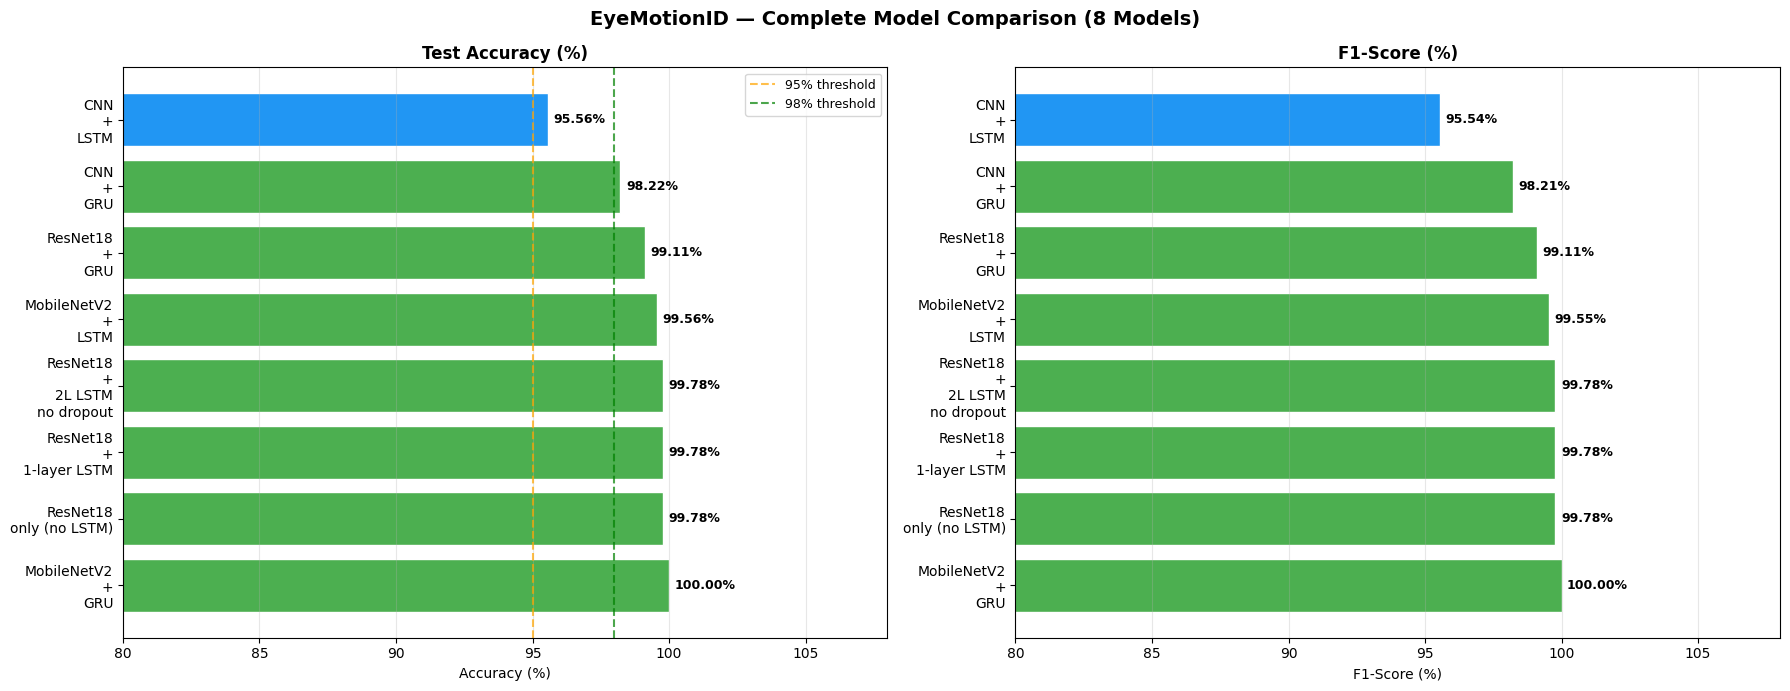

✓ Saved → complete_model_comparison.png


In [9]:
# Cell 7 — Final comparison chart
names     = [n for n,_ in sorted_all]
test_accs = [r['test_acc']*100 for _,r in sorted_all]
f1_scores = [r['f1']*100 for _,r in sorted_all]
colors    = ['#4CAF50' if a>=98 else '#2196F3' if a>=95
             else '#FF9800' if a>=90 else '#F44336'
             for a in test_accs]

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle("EyeMotionID — Complete Model Comparison (8 Models)",
             fontsize=14, fontweight='bold')

xlabels = [n.replace(' + ','\n+\n').replace(' only','\nonly')
           .replace(' no dropout','\nno dropout') for n in names]

# accuracy
bars1 = axes[0].barh(xlabels, test_accs, color=colors, edgecolor='white')
axes[0].set_title("Test Accuracy (%)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Accuracy (%)")
axes[0].set_xlim(80, 108)
axes[0].axvline(x=95, color='orange', linestyle='--',
                alpha=0.7, label='95% threshold')
axes[0].axvline(x=98, color='green', linestyle='--',
                alpha=0.7, label='98% threshold')
for bar, acc in zip(bars1, test_accs):
    axes[0].text(acc+0.2, bar.get_y()+bar.get_height()/2,
                 f"{acc:.2f}%", va='center', fontsize=9, fontweight='bold')
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3, axis='x')

# F1
bars2 = axes[1].barh(xlabels, f1_scores, color=colors, edgecolor='white')
axes[1].set_title("F1-Score (%)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("F1-Score (%)")
axes[1].set_xlim(80, 108)
for bar, f1 in zip(bars2, f1_scores):
    axes[1].text(f1+0.2, bar.get_y()+bar.get_height()/2,
                 f"{f1:.2f}%", va='center', fontsize=9, fontweight='bold')
axes[1].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig(f"{OUTPUT}/complete_model_comparison.png", dpi=100)
plt.show()
print("✓ Saved → complete_model_comparison.png")

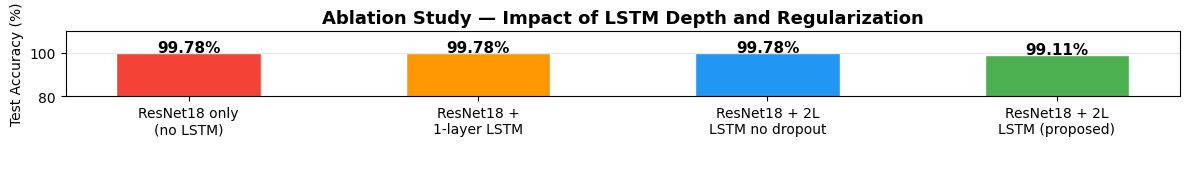

✓ Saved → ablation_study.png


In [10]:
# Cell 8 — Ablation study chart
ablation_names = [
    'ResNet18 only\n(no LSTM)',
    'ResNet18 +\n1-layer LSTM',
    'ResNet18 + 2L\nLSTM no dropout',
    'ResNet18 + 2L\nLSTM (proposed)',
]
ablation_accs = [
    new_results['ResNet18 only (no LSTM)']['test_acc']*100,
    new_results['ResNet18 + 1-layer LSTM']['test_acc']*100,
    new_results['ResNet18 + 2L LSTM no dropout']['test_acc']*100,
    new_results.get('ResNet18 + GRU', {}).get('test_acc', 0)*100,
]
ablation_colors = ['#F44336','#FF9800','#2196F3','#4CAF50']
ablation_labels = [
    'No temporal\nmodeling',
    'Shallow\ntemporal',
    'No\nregularization',
    'Full proposed\nmodel'
]

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(ablation_names, ablation_accs,
              color=ablation_colors, edgecolor='white', width=0.5)

for bar, acc, label in zip(bars, ablation_accs, ablation_labels):
    ax.text(bar.get_x()+bar.get_width()/2,
            bar.get_height()+0.5,
            f"{acc:.2f}%", ha='center', fontsize=11, fontweight='bold')
    ax.text(bar.get_x()+bar.get_width()/2,
            bar.get_height()/2,
            label, ha='center', va='center',
            fontsize=9, color='white', fontweight='bold')

ax.set_title("Ablation Study — Impact of LSTM Depth and Regularization",
             fontsize=13, fontweight='bold')
ax.set_ylabel("Test Accuracy (%)")
ax.set_ylim(80, 110)
ax.grid(True, alpha=0.3, axis='y')

# arrows showing improvement
for i in range(len(ablation_accs)-1):
    diff = ablation_accs[i+1] - ablation_accs[i]
    if diff > 0:
        ax.annotate(f"+{diff:.1f}%",
                    xy=(i+1, ablation_accs[i+1]+2),
                    xytext=(i, ablation_accs[i]+2),
                    arrowprops=dict(arrowstyle='->', color='green', lw=2),
                    fontsize=9, color='green', fontweight='bold')

plt.tight_layout()
plt.savefig(f"{OUTPUT}/ablation_study.png", dpi=100)
plt.show()
print("✓ Saved → ablation_study.png")

In [11]:
# Cell 9 — Final summary
print("=" * 60)
print("   ADVANCED MODEL COMPARISON SUMMARY")
print("=" * 60)
print()
print("All 8 models evaluated on EyeDentify (15 users)")
print()
print("Rankings:")
for rank, (name, r) in enumerate(sorted_all, 1):
    print(f"  #{rank:<3} {name:<35} {r['test_acc']:.2%}")
print()
print("Ablation Findings:")
r_no_lstm  = new_results['ResNet18 only (no LSTM)']['test_acc']*100
r_1layer   = new_results['ResNet18 + 1-layer LSTM']['test_acc']*100
r_nodrop   = new_results['ResNet18 + 2L LSTM no dropout']['test_acc']*100
r_gru      = new_results['ResNet18 + GRU']['test_acc']*100
print(f"  ResNet18 only (no LSTM)      : {r_no_lstm:.2f}%")
print(f"  + 1-layer LSTM               : {r_1layer:.2f}% (+{r_1layer-r_no_lstm:.2f}%)")
print(f"  + 2-layer LSTM no dropout    : {r_nodrop:.2f}% (+{r_nodrop-r_1layer:.2f}%)")
print(f"  + 2-layer LSTM with dropout  : {r_gru:.2f}% (+{r_gru-r_nodrop:.2f}%)")
print()
print("Plots saved:")
print("  ✓ complete_model_comparison.png")
print("  ✓ ablation_study.png")
print("=" * 60)

   ADVANCED MODEL COMPARISON SUMMARY

All 8 models evaluated on EyeDentify (15 users)

Rankings:
  #1   MobileNetV2 + GRU                   100.00%
  #2   ResNet18 only (no LSTM)             99.78%
  #3   ResNet18 + 1-layer LSTM             99.78%
  #4   ResNet18 + 2L LSTM no dropout       99.78%
  #5   MobileNetV2 + LSTM                  99.56%
  #6   ResNet18 + GRU                      99.11%
  #7   CNN + GRU                           98.22%
  #8   CNN + LSTM                          95.56%

Ablation Findings:
  ResNet18 only (no LSTM)      : 99.78%
  + 1-layer LSTM               : 99.78% (+0.00%)
  + 2-layer LSTM no dropout    : 99.78% (+0.00%)
  + 2-layer LSTM with dropout  : 99.11% (+-0.67%)

Plots saved:
  ✓ complete_model_comparison.png
  ✓ ablation_study.png
